## 1. Cargar calibración y mapas (Tutorial 6, celda 53), con las claves que escribe la herramienta de la cátedra.

In [1]:
import os, glob, json, pickle
import cv2
import numpy as np
from matplotlib import pyplot as plt
from i308_utils import show_images


def read_img(path):
    # cv2.imread devuelve None con rutas no ASCII en Windows (ej. "Visión")
    if not os.path.exists(path):
        raise FileNotFoundError(f"No existe {path}")
    img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"No se pudo decodificar {path}")
    return img


def write_img(path, img):
    ok, buf = cv2.imencode(os.path.splitext(path)[1], img)
    if not ok:
        raise ValueError(f"No se pudo codificar {path}")
    buf.tofile(path)

In [2]:
BASE = "." if os.path.isdir("datasets") else ".."

calib_file = os.path.join(BASE, "calibration", "stereo_calibration.pkl")
maps_file = os.path.join(BASE, "calibration", "stereo_maps.pkl")
captures_dir = os.path.join(BASE, "datasets", "stereo_stitch_charuco", "captures")
rect_dir = os.path.join(BASE, "datasets", "stereo_stitch_charuco", "rect")

with open(calib_file, "rb") as f:
    calibration = pickle.load(f)
with open(maps_file, "rb") as f:
    maps = pickle.load(f)

left_K, left_dist = calibration["left_K"], calibration["left_dist"]
right_K, right_dist = calibration["right_K"], calibration["right_dist"]
R, T = calibration["R"], calibration["T"]
print("image_size:", calibration["image_size"], " baseline:", np.linalg.norm(T).round(2), "mm")

left_map_x, left_map_y = maps["left_map_x"], maps["left_map_y"]
right_map_x, right_map_y = maps["right_map_x"], maps["right_map_y"]
P1, P2, Q = maps["P1"], maps["P2"], maps["Q"]

image_size: (1280, 720)  baseline: 60.17 mm


## 2. Rectificar un par y mirarlo

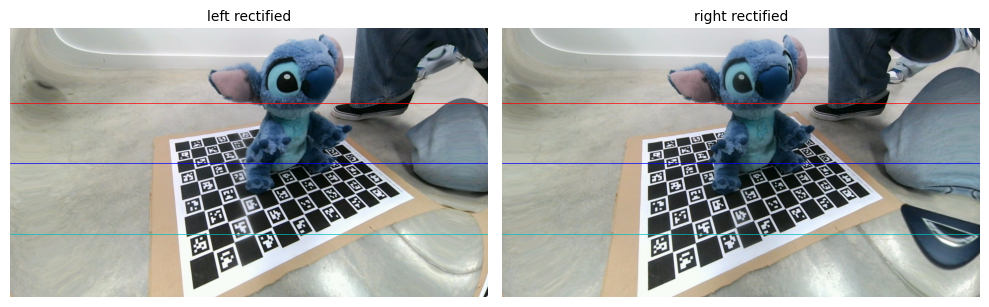

In [3]:
i = 13
left = read_img(os.path.join(captures_dir, f"left_{i}.jpg"))
right = read_img(os.path.join(captures_dir, f"right_{i}.jpg"))

left_rect = cv2.remap(left, left_map_x, left_map_y, cv2.INTER_LINEAR)
right_rect = cv2.remap(right, right_map_x, right_map_y, cv2.INTER_LINEAR)

fig, axes = show_images([left_rect, right_rect], ["left rectified", "right rectified"], show=False)
for y, c in zip([200, 360, 550], ["r", "b", "c"]):
    axes[0].axhline(y=y, color=c, linewidth=0.5)
    axes[1].axhline(y=y, color=c, linewidth=0.5)
plt.show()

## 3- Rectificar los 27 pares

In [4]:
os.makedirs(rect_dir, exist_ok=True)

def numero(path):
    return int(os.path.basename(path).split("_")[-1].split(".")[0])

left_files = sorted(glob.glob(os.path.join(captures_dir, "left_*.jpg")), key=numero)
for lf in left_files:
    idx = numero(lf)
    rf = os.path.join(captures_dir, f"right_{idx}.jpg")
    left_rect = cv2.remap(read_img(lf), left_map_x, left_map_y, cv2.INTER_LINEAR)
    right_rect = cv2.remap(read_img(rf), right_map_x, right_map_y, cv2.INTER_LINEAR)
    write_img(os.path.join(rect_dir, f"rect_left_{idx}.png"), left_rect)
    write_img(os.path.join(rect_dir, f"rect_right_{idx}.png"), right_rect)
print("listo:", len(left_files), "pares rectificados en", rect_dir)

listo: 27 pares rectificados en ../datasets/stereo_stitch_charuco/rect


## 4. Archivo de calibración para `stereodemo`

La tool interactiva `stereodemo` no lee los `.pkl`: necesita un `stereodemo_calibration.json` en la carpeta de pares rectificados con la cámara **ya rectificada** (focal y centro de `P1`/`P2`, baseline en metros). Con esto se puede correr `stereodemo datasets/stereo_stitch_charuco/rect` para ajustar los parámetros de disparidad a mano antes de fijarlos en la sección 6.

In [5]:
h, w = left_rect.shape[:2]
calib_json = {
    "width": w, "height": h,
    "baseline_meters": float(np.linalg.norm(T)) / 1000,
    "fx": float(P1[0, 0]), "fy": float(P1[1, 1]),
    "cx0": float(P1[0, 2]), "cx1": float(P2[0, 2]), "cy": float(P1[1, 2]),
    "depth_range": [0.2, 3.0],
    "left_image_rect_normalized": [0, 0, 1, 1],
}
with open(os.path.join(rect_dir, "stereodemo_calibration.json"), "w") as f:
    json.dump(calib_json, f, indent=2)
print(json.dumps(calib_json, indent=2))

{
  "width": 1280,
  "height": 720,
  "baseline_meters": 0.06016896206128554,
  "fx": 405.88681301544904,
  "fy": 405.88681301544904,
  "cx0": 631.0462799072266,
  "cx1": 631.0462799072266,
  "cy": 352.4043731689453,
  "depth_range": [
    0.2,
    3.0
  ],
  "left_image_rect_normalized": [
    0,
    0,
    1,
    1
  ]
}


## 5. Tablero ChArUco y verificación de la calibración

El tablero de nuestras capturas **no es** el `5x7 / DICT_6X6_250` del ejemplo de la cátedra. Su geometría está impresa en el borde del propio tablero:

> `Charuco Board | Dict: DICT_5X5_100 | Grid: 9x13 | Square: 42.0mm | Marker: 31.5mm`

Es decir, 9 casilleros en x por 13 en y, con 58 marcadores (IDs 0 a 57, que es justo lo que se detecta) y 8 x 12 = 96 esquinas internas. Todo el pipeline queda en **milímetros**.

El `.pkl` de la tool no guarda el RMS de la calibración. Para tener una medida de calidad usamos el tablero como dato **independiente** de la calibración:

1. **Error de reproyección estéreo**: en cada par se estima la pose del tablero con la cámara izquierda (`solvePnP`), se la lleva a la cámara derecha con los extrínsecos `R, T` de la calibración y se reproyectan las esquinas. Si `K`, `dist`, `R` y `T` son correctos, el error en la derecha es chico.
2. **Escala métrica**: se triangulan las esquinas detectadas en ambas imágenes con `P1`, `P2` y se mide la distancia entre esquinas vecinas, que debería ser 42,0 mm.

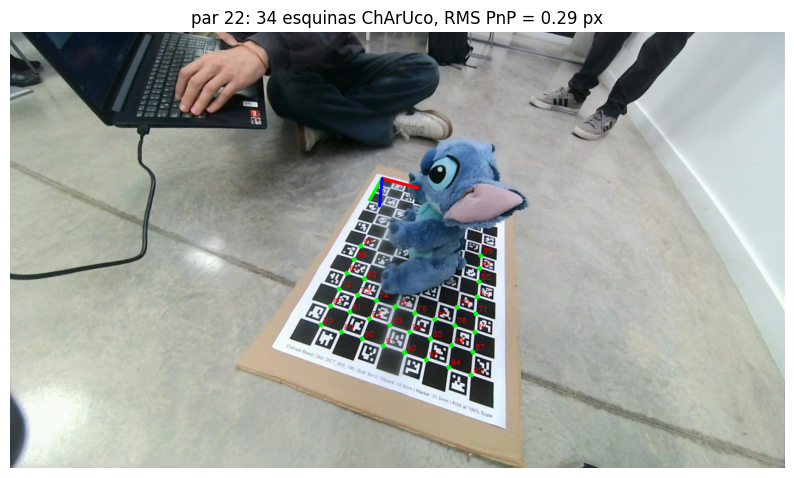

In [6]:
ARUCO_DICT = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_5X5_100)
SQUARES = (9, 13)        # (x, y)
SQUARE_MM, MARKER_MM = 42.0, 31.5
board = cv2.aruco.CharucoBoard(SQUARES, SQUARE_MM, MARKER_MM, ARUCO_DICT)
charuco_detector = cv2.aruco.CharucoDetector(board)
corners3d_board = board.getChessboardCorners()   # (96, 3) en mm, z = 0
N_CORNERS_X = SQUARES[0] - 1


def detect_charuco(img):
    # devuelve {id_esquina: (u, v)} en la imagen original (sin rectificar)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    ch_corners, ch_ids, _, _ = charuco_detector.detectBoard(gray)
    if ch_ids is None:
        return {}
    return dict(zip(ch_ids.ravel().tolist(), ch_corners.reshape(-1, 2).astype(np.float64)))


def estimate_pose(img, K, dist, min_corners=8):
    # Pose del tablero en la cámara: X_cam = R_wc @ X_board + t_wc.
    # IPPE (específico para puntos coplanares) + descarte iterativo de esquinas mal detectadas.
    det = detect_charuco(img)
    if len(det) < min_corners:
        return None
    ids = np.array(sorted(det))
    obj = corners3d_board[ids].astype(np.float64)
    img_pts = np.array([det[k] for k in ids])
    keep = np.ones(len(ids), bool)
    for _ in range(3):
        ok, rvec, tvec = cv2.solvePnP(obj[keep], img_pts[keep], K, dist, flags=cv2.SOLVEPNP_IPPE)
        rvec, tvec = cv2.solvePnPRefineLM(obj[keep], img_pts[keep], K, dist, rvec, tvec)
        proj, _ = cv2.projectPoints(obj, rvec, tvec, K, dist)
        err = np.linalg.norm(proj.reshape(-1, 2) - img_pts, axis=1)
        new_keep = err < max(2.0, 3 * np.median(err))
        if (new_keep == keep).all():
            break
        keep = new_keep
        if keep.sum() < min_corners:
            return None
    return {"rvec": rvec, "tvec": tvec, "n_det": len(ids), "n_used": int(keep.sum()),
            "rms": float(np.sqrt(np.mean(err[keep] ** 2)))}


img0 = read_img(os.path.join(captures_dir, "left_22.jpg"))
det0 = detect_charuco(img0)
vis = img0.copy()
for k, (u, v) in det0.items():
    cv2.circle(vis, (int(u), int(v)), 4, (0, 255, 0), -1)
    cv2.putText(vis, str(k), (int(u) + 4, int(v) - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
pose0 = estimate_pose(img0, left_K, left_dist)
cv2.drawFrameAxes(vis, left_K, left_dist, pose0["rvec"], pose0["tvec"], 120, 3)
plt.figure(figsize=(10, 6)); plt.imshow(vis[:, :, ::-1]); plt.axis("off")
plt.title(f"par 22: {len(det0)} esquinas ChArUco, RMS PnP = {pose0['rms']:.2f} px"); plt.show()

In [7]:
R1, R2 = maps["R1"], maps["R2"]
rows, err_left, err_right, square_dists = [], [], [], []

for lf in left_files:
    idx = numero(lf)
    imgL = read_img(lf)
    imgR = read_img(os.path.join(captures_dir, f"right_{idx}.jpg"))
    dL, dR = detect_charuco(imgL), detect_charuco(imgR)
    common = sorted(set(dL) & set(dR))
    pose = estimate_pose(imgL, left_K, left_dist)
    if pose is None or len(common) < 8:
        rows.append((idx, len(common), None, None, None)); continue
    X = corners3d_board[common].astype(np.float64)
    pl = np.array([dL[k] for k in common]); pr = np.array([dR[k] for k in common])

    # reproyección izquierda (pose propia) y derecha (pose izquierda + R, T de la calibración)
    projL, _ = cv2.projectPoints(X, pose["rvec"], pose["tvec"], left_K, left_dist)
    Rl, _ = cv2.Rodrigues(pose["rvec"])
    rv_r, _ = cv2.Rodrigues(R @ Rl)
    projR, _ = cv2.projectPoints(X, rv_r, R @ pose["tvec"] + T, right_K, right_dist)
    eL = np.linalg.norm(projL.reshape(-1, 2) - pl, axis=1)
    eR = np.linalg.norm(projR.reshape(-1, 2) - pr, axis=1)
    good = eL < 2.0                      # mismas esquinas que aceptó el PnP
    err_left += list(eL[good]); err_right += list(eR[good])

    # triangulación en el marco rectificado y lado del casillero
    ul = cv2.undistortPoints(pl.reshape(-1, 1, 2), left_K, left_dist, R=R1, P=P1).reshape(-1, 2)
    ur = cv2.undistortPoints(pr.reshape(-1, 1, 2), right_K, right_dist, R=R2, P=P2).reshape(-1, 2)
    Xh = cv2.triangulatePoints(P1, P2, ul.T, ur.T)
    Xt = (Xh[:3] / Xh[3]).T
    pos = {k: j for j, k in enumerate(common)}
    d = [np.linalg.norm(Xt[pos[k]] - Xt[pos[n]])
         for k in common if good[pos[k]]
         for n in ([k + 1] if k % N_CORNERS_X != N_CORNERS_X - 1 else []) + [k + N_CORNERS_X]
         if n in pos and good[pos[n]]]
    square_dists += d
    rows.append((idx, len(common), eR[good].mean(), np.median(ul[:, 1] - ur[:, 1]), np.median(d) if d else None))

rms = lambda e: float(np.sqrt(np.mean(np.square(e)))) if len(e) else float("nan")

def fmt(x, width, prec=2):
    if x is None or not np.isfinite(x):
        return f"{'-':>{width}}"
    return f"{float(x):>{width}.{prec}f}"

print(f"{'par':>4} {'esq.':>5} {'err der [px]':>13} {'dy rect [px]':>13} {'lado [mm]':>10}")
for r in rows:
    if r[2] is None:
        print(f"{r[0]:>4} {r[1]:>5}   tablero no detectado en ambas")
    else:
        print(f"{r[0]:>4} {r[1]:>5} {fmt(r[2], 13)} {fmt(r[3], 13)} {fmt(r[4], 10)}")

print(f"\nRMS reproyección izquierda (PnP)        : {rms(err_left):.3f} px")
print(f"RMS reproyección derecha (vía R, T)      : {rms(err_right):.3f} px")
print(f"lado del casillero triangulado            : mediana {np.median(square_dists):.2f} mm, "
      f"media {np.mean(square_dists):.2f} ± {np.std(square_dists):.2f} mm  (real 42,0 mm, n = {len(square_dists)})")

 par  esq.  err der [px]  dy rect [px]  lado [mm]
   0    17          1.92         -1.62      41.92
   1    10          2.98         -1.80      44.63
   2    28          1.38         -1.05      41.74
   3    30          1.47         -1.26      41.50
   4    33          1.34         -1.18      41.76
   5    33          1.21         -1.02      42.53
   6    25          1.70         -1.51      41.61
   7    38          1.74         -1.16      41.21
   8    42          1.18         -0.96      41.65
   9    30          1.11         -0.86      41.92
  10    40          0.86         -0.83      42.23
  11    22          1.27         -1.03      42.12
  12    48          0.96         -0.71      42.42
  13    43          1.12         -0.85      42.32
  14    40          0.89         -0.69      42.44
  15    42          0.93         -0.75      42.50
  16    46          0.82         -0.58      42.43
  17    13          0.82         -0.24      41.98
  18    13          0.61         -0.26      42.15


**Lectura**: el error en la cámara derecha (≈1 px) mide de forma conjunta los intrínsecos y los extrínsecos `R, T`. El lado del casillero triangulado da ≈42,2 mm frente a 42,0 mm reales (≈0,4 %), así que **la calibración es métrica**: la escala de toda la reconstrucción viene del baseline `T` en mm. La columna `dy rect` muestra un desfasaje vertical residual de 0,3 a 1,5 px entre imágenes rectificadas, mayor en los pares 0 a 7 (tablero en el borde de la imagen). Es aceptable para SGBM, y es un punto para la discusión: recalibrar cubriendo mejor los bordes lo bajaría.

> Para el informe: si conservan la salida de consola de `calib-stereo`, reporten también ese RMS (es el de las imágenes de calibración); el de esta celda es una validación sobre datos independientes.

## 6. Disparidad, etapa 4.2.1 (SGBM)

Usamos `StereoSGBM` de OpenCV. Los parámetros dependen de la cámara y de la escena, no de cada foto, así que se fijan una vez para los 27 pares (se pueden afinar antes en `stereodemo`):

| parámetro | valor | por qué |
|---|---|---|
| `minDisparity`, `numDisparities` | 8, 144 | busca d en [8, 152) px. Con z = f·B/d ≈ 24 400/d mm cubre de ~16 cm a ~3 m; el peluche está entre 25 y 60 cm (d ≈ 40 a 100 px) |
| `blockSize` | 5 | ventana chica: conserva bordes (orejas) y el peluche tiene textura suficiente |
| `P1`, `P2` | 8·3·5², 32·3·5² | penalidades de suavidad recomendadas por OpenCV (P2 > P1 penaliza saltos grandes) |
| `uniquenessRatio` | 10 | descarta matches ambiguos |
| `speckleWindowSize`, `speckleRange` | 200, 2 | elimina manchas chicas inconsistentes |
| `disp12MaxDiff` | 1 | chequeo izquierda-derecha |
| `mode` | `SGBM_3WAY` | más rápido que `HH` con calidad similar |

OpenCV devuelve la disparidad como `int16` multiplicada por 16: se divide por 16 y los inválidos (≤ `minDisparity`) se marcan con NaN.

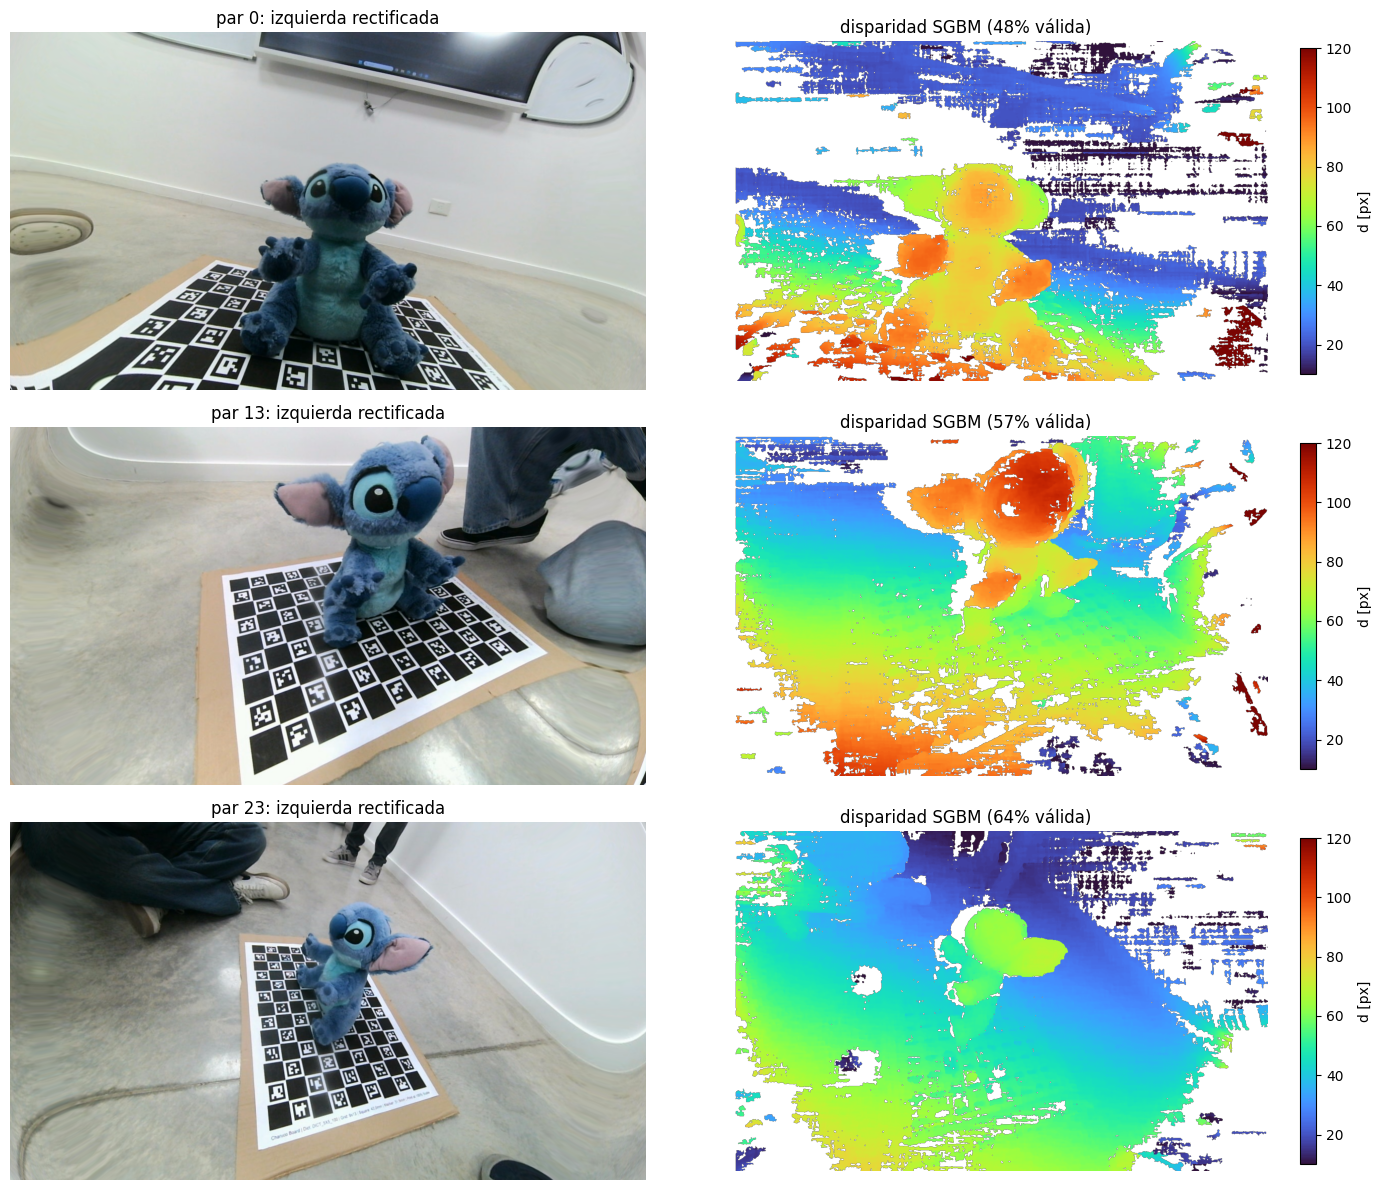

In [8]:
SGBM_PARAMS = dict(minDisparity=8, numDisparities=144, blockSize=5,
                   P1=8 * 3 * 5 ** 2, P2=32 * 3 * 5 ** 2, disp12MaxDiff=1,
                   uniquenessRatio=10, speckleWindowSize=200, speckleRange=2,
                   preFilterCap=63, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
sgbm = cv2.StereoSGBM_create(**SGBM_PARAMS)


def rectify_pair(idx):
    l = read_img(os.path.join(captures_dir, f"left_{idx}.jpg"))
    r = read_img(os.path.join(captures_dir, f"right_{idx}.jpg"))
    return (l,
            cv2.remap(l, left_map_x, left_map_y, cv2.INTER_LINEAR),
            cv2.remap(r, right_map_x, right_map_y, cv2.INTER_LINEAR))


def compute_disparity(left_rect, right_rect):
    disp = sgbm.compute(left_rect, right_rect).astype(np.float32) / 16.0
    disp[disp <= SGBM_PARAMS["minDisparity"]] = np.nan
    return disp


fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for row, idx in enumerate([0, 13, 23]):
    _, lr, rr = rectify_pair(idx)
    disp = compute_disparity(lr, rr)
    axes[row, 0].imshow(lr[:, :, ::-1]); axes[row, 0].set_title(f"par {idx}: izquierda rectificada")
    im = axes[row, 1].imshow(disp, cmap="turbo", vmin=10, vmax=120)
    axes[row, 1].set_title(f"disparidad SGBM ({np.isfinite(disp).mean():.0%} válida)")
    fig.colorbar(im, ax=axes[row, 1], fraction=0.025, label="d [px]")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.show()

## 7. Nube local, etapa 4.2.2

`cv.reprojectImageTo3D(disp, Q)` aplica, para cada píxel, $[X\ Y\ Z\ W]^T = Q\,[u\ v\ d\ 1]^T$ y devuelve $(X/W, Y/W, Z/W)$. Con nuestra `Q` eso es exactamente

$$Z = \frac{f\,B}{d},\qquad X = \frac{(u-c_x)\,Z}{f},\qquad Y = \frac{(v-c_y)\,Z}{f}$$

con $f = 405{,}9$ px y $B = 60{,}17$ mm, en el sistema de la **cámara izquierda rectificada** y en mm.

Filtros por píxel antes de pasar a 3D:
- disparidad válida;
- rango de profundidad 150 a 1000 mm (fuera de eso es fondo del aula o ruido);
- **bordes de profundidad**: en los saltos de disparidad SGBM interpola entre frente y fondo y genera "flying pixels" (el halo gris alrededor de las orejas). Se descartan los píxeles donde la disparidad varía más de 3 px en un vecindario de 5x5.

par 13: 400,826 puntos locales (43% de los píxeles)
píxel (201,344): d = 60.00 px -> f·B/d = 407.0 mm, reprojectImageTo3D z = 407.0 mm


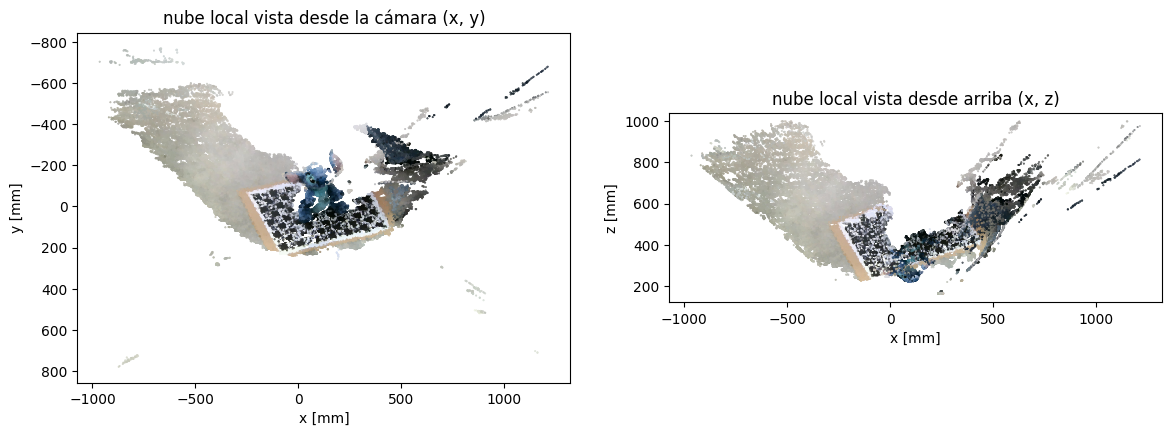

In [9]:
Z_RANGE_MM = (150, 1000)
EDGE_MAX_DD = 3.0


def local_cloud(disp, left_rect):
    pts = cv2.reprojectImageTo3D(np.nan_to_num(disp, nan=0.0), Q)      # (H, W, 3) en mm
    d0 = np.nan_to_num(disp, nan=0.0)
    kernel = np.ones((5, 5), np.uint8)
    edges = (cv2.dilate(d0, kernel) - cv2.erode(d0, kernel)) > EDGE_MAX_DD
    z = pts[..., 2]
    mask = np.isfinite(disp) & ~edges & (z > Z_RANGE_MM[0]) & (z < Z_RANGE_MM[1])
    colors = left_rect[mask][:, ::-1].astype(np.float32) / 255.0       # BGR -> RGB
    return pts[mask].astype(np.float64), colors, mask


idx = 13
_, lr, rr = rectify_pair(idx)
disp = compute_disparity(lr, rr)
X_loc, C_loc, mask = local_cloud(disp, lr)
print(f"par {idx}: {len(X_loc):,} puntos locales ({mask.mean():.0%} de los píxeles)")

# chequeo de la fórmula z = f·B/d en un píxel cualquiera
v, u = np.argwhere(mask)[len(X_loc) // 2]
f, B = P1[0, 0], -P2[0, 3] / P1[0, 0]
print(f"píxel ({u},{v}): d = {disp[v, u]:.2f} px -> f·B/d = {f * B / disp[v, u]:.1f} mm, "
      f"reprojectImageTo3D z = {cv2.reprojectImageTo3D(disp, Q)[v, u, 2]:.1f} mm")

sub = np.random.default_rng(0).choice(len(X_loc), min(150_000, len(X_loc)), replace=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_loc[sub, 0], X_loc[sub, 1], c=C_loc[sub], s=0.2); ax[0].invert_yaxis()
ax[0].set_title("nube local vista desde la cámara (x, y)"); ax[0].set_aspect("equal")
ax[1].scatter(X_loc[sub, 0], X_loc[sub, 2], c=C_loc[sub], s=0.2)
ax[1].set_title("nube local vista desde arriba (x, z)"); ax[1].set_aspect("equal")
for a in ax: a.set_xlabel("x [mm]")
ax[0].set_ylabel("y [mm]"); ax[1].set_ylabel("z [mm]")
plt.show()

## 8. Pose global y transformación, etapas 4.2.3 y 4.2.4

**Pose**: en la imagen izquierda **original** (sin rectificar) detectamos las esquinas ChArUco, cuyas coordenadas en el tablero conocemos en mm (z = 0). `solvePnP` encuentra $(\mathbf r, \mathbf t)$ tal que

$$\mathbf X_{cam} = R_{wc}\,\mathbf X_{mundo} + \mathbf t,\qquad R_{wc} = \text{Rodrigues}(\mathbf r).$$

El vector de Rodrigues $\mathbf r$ codifica la rotación en 3 números: su dirección es el eje de giro y su norma el ángulo en radianes. `cv.Rodrigues` lo convierte en la matriz $3\times3$. Usamos `SOLVEPNP_IPPE`, específico para puntos coplanares, refinamos con Levenberg-Marquardt y descartamos esquinas con error de reproyección alto. El "mundo" es el sistema del tablero: origen en la esquina superior izquierda, x a lo largo de los 9 casilleros, y a lo largo de los 13, **z hacia adentro del tablero** (los puntos del peluche tienen z < 0).

**Transformación**: hay un detalle que importa. La nube de `reprojectImageTo3D` está en la cámara izquierda **rectificada**, que está rotada $R_1$ respecto de la cámara izquierda original ($\mathbf X_{rect} = R_1 \mathbf X_{cam}$). Por eso la cuenta completa es

$$\mathbf X_{mundo} = R_{wc}^T\left(R_1^T\,\mathbf X_{rect} - \mathbf t\right).$$

(Alternativa equivalente: detectar el tablero en la imagen rectificada usando `P1[:, :3]` y distorsión cero; ahí $R_1$ ya no aparece.)

Se descartan los pares sin tablero visible o con RMS de PnP > 2 px.

In [10]:
MAX_POSE_RMS = 2.0
views = []        # una entrada por par aceptado

for lf in left_files:
    idx = numero(lf)
    left, lr, rr = rectify_pair(idx)
    pose = estimate_pose(left, left_K, left_dist)
    if pose is None:
        print(f"par {idx:>2}: tablero no detectado -> descartado"); continue
    if pose["rms"] > MAX_POSE_RMS:
        print(f"par {idx:>2}: RMS PnP {pose['rms']:.2f} px -> descartado"); continue

    disp = compute_disparity(lr, rr)
    X_rect, colors, _ = local_cloud(disp, lr)

    R_wc, _ = cv2.Rodrigues(pose["rvec"])
    t_wc = pose["tvec"].reshape(3)
    X_cam = X_rect @ R1                 # fila a fila: R1^T · X_rect
    X_world = (X_cam - t_wc) @ R_wc     # fila a fila: R_wc^T · (X_cam - t)
    cam_center = -R_wc.T @ t_wc         # posición de la cámara izquierda en el mundo

    views.append(dict(idx=idx, X=X_world, C=colors, R_wc=R_wc, t_wc=t_wc, center=cam_center, **pose))
    print(f"par {idx:>2}: {pose['n_used']:>2}/{pose['n_det']:<2} esquinas, RMS PnP {pose['rms']:.2f} px, "
          f"{len(X_world):>7,} pts, cámara en {np.round(cam_center).astype(int)} mm")

print(f"\n{len(views)} de {len(left_files)} pares aceptados")

par  0: 19/20 esquinas, RMS PnP 0.78 px, 171,169 pts, cámara en [-133  209 -235] mm
par  1: 10/10 esquinas, RMS PnP 0.95 px, 215,294 pts, cámara en [-112  107 -188] mm
par  2: 30/31 esquinas, RMS PnP 0.64 px, 246,953 pts, cámara en [ -77  454 -185] mm
par  3: 33/33 esquinas, RMS PnP 0.36 px, 350,057 pts, cámara en [ 154  694 -314] mm
par  4: 35/35 esquinas, RMS PnP 0.38 px, 358,280 pts, cámara en [ 116  668 -312] mm
par  5: 35/35 esquinas, RMS PnP 0.30 px, 451,516 pts, cámara en [  52  501 -419] mm
par  6: 25/25 esquinas, RMS PnP 0.46 px, 347,662 pts, cámara en [ 312  560 -292] mm
par  7: 39/40 esquinas, RMS PnP 0.60 px, 307,706 pts, cámara en [ 436  439 -310] mm
par  8: 35/42 esquinas, RMS PnP 0.68 px, 312,336 pts, cámara en [ 469  323 -313] mm
par  9: 28/30 esquinas, RMS PnP 0.60 px, 368,853 pts, cámara en [ 471  219 -314] mm
par 10: 40/40 esquinas, RMS PnP 0.28 px, 427,725 pts, cámara en [ 431  105 -346] mm
par 11: 24/24 esquinas, RMS PnP 0.67 px, 413,296 pts, cámara en [ 361   10 -

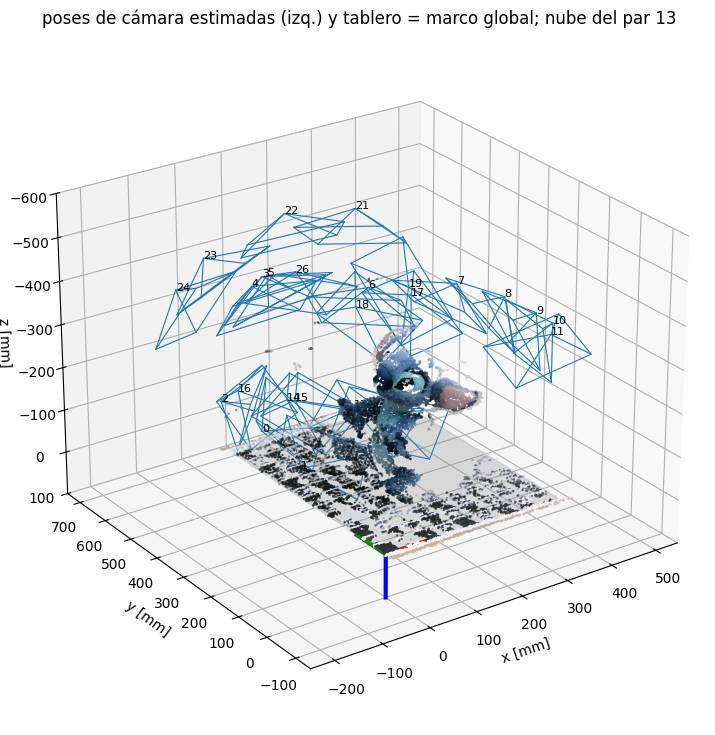

In [11]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def frustum_world(view, scale=60.0):
    # pirámide de la cámara izquierda (en mm) llevada al mundo
    w, h = calibration["image_size"]
    Kinv = np.linalg.inv(left_K)
    rays = np.array([Kinv @ [u, v, 1.0] for u, v in [(0, 0), (w, 0), (w, h), (0, h)]]) * scale
    return view["center"], (rays - view["t_wc"]) @ view["R_wc"]

fig = plt.figure(figsize=(11, 9)); ax = fig.add_subplot(projection="3d")
bw, bh = SQUARES[0] * SQUARE_MM, SQUARES[1] * SQUARE_MM
ax.add_collection3d(Poly3DCollection([[(0, 0, 0), (bw, 0, 0), (bw, bh, 0), (0, bh, 0)]], alpha=0.25, color="gray"))
for v in views:
    c, corners = frustum_world(v)
    for p in corners: ax.plot(*zip(c, p), color="tab:blue", lw=0.8)
    ax.plot(*np.vstack([corners, corners[:1]]).T, color="tab:blue", lw=0.8)
    ax.text(*c, str(v["idx"]), fontsize=8)
# eje global
for vec, col in zip(np.eye(3) * 100, ["r", "g", "b"]):
    ax.plot(*zip([0, 0, 0], vec), color=col, lw=3)
sub = views[[v["idx"] for v in views].index(13)]
s = np.random.default_rng(0).choice(len(sub["X"]), 60_000, replace=False)
inside = ((sub["X"][s, 2] < 5) & (sub["X"][s, 2] > -350) & (sub["X"][s, 0] > -20) & (sub["X"][s, 0] < 400)
          & (sub["X"][s, 1] > -20) & (sub["X"][s, 1] < 570))
ax.scatter(*sub["X"][s][inside].T, c=sub["C"][s][inside], s=0.3)
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]"); ax.set_zlabel("z [mm]")
ax.set_xlim(-250, 550); ax.set_ylim(-150, 750); ax.set_zlim(-600, 100)
ax.invert_zaxis(); ax.view_init(elev=25, azim=-125)
ax.set_title("poses de cámara estimadas (izq.) y tablero = marco global; nube del par 13")
plt.show()

Las cámaras forman una órbita alrededor del tablero, a 20 a 55 cm sobre su plano (z negativo), y eso coincide con cómo se movió la cámara al capturar.

## 9. Fusión y optimización, etapa 4.3

Se acumulan todas las nubes en el marco global y se optimiza en Open3D:

1. **Caja (filtrado espacial)**: `OrientedBoundingBox` que encierra la zona del peluche sobre el tablero (x 40 a 360, y 80 a 500, z de −360 a −4 mm), con `get_point_indices_within_bounding_box` y `select_by_index`.
2. **Submuestreo** `voxel_down_sample(2 mm)`: las ~25 vistas se superponen y hay mucha redundancia. 2 mm conserva el detalle del pelaje y de las orejas.
3. **Outliers**: `remove_statistical_outlier(30 vecinos, 1,5 σ)` y después `remove_radius_outlier(12 puntos en 6 mm)` para puntos flotantes.
4. **Plano del tablero**: `segment_plane` (RANSAC, 10 mm) encuentra el tablero dentro de la caja y lo quitamos para quedarnos solo con el objeto.
5. **Componente principal**: `cluster_dbscan` (6 mm) y nos quedamos con el cluster más grande (el peluche), lo que descarta restos sueltos.

In [12]:
import open3d as o3d

def to_pcd(X, C):
    p = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(X))
    p.colors = o3d.utility.Vector3dVector(C.astype(np.float64))
    return p

pcd_all = to_pcd(np.vstack([v["X"] for v in views]), np.vstack([v["C"] for v in views]))
steps = [("nube global completa", pcd_all)]

box = o3d.geometry.AxisAlignedBoundingBox(np.array([40.0, 80.0, -360.0]), np.array([360.0, 500.0, -4.0]))
obb = o3d.geometry.OrientedBoundingBox.create_from_axis_aligned_bounding_box(box)
obb.color = (1, 0, 0)
pcd_box = pcd_all.select_by_index(obb.get_point_indices_within_bounding_box(pcd_all.points))
steps.append(("1. caja", pcd_box))

pcd_vox = pcd_box.voxel_down_sample(voxel_size=2.0)
steps.append(("2. voxel 2 mm", pcd_vox))

pcd_stat, _ = pcd_vox.remove_statistical_outlier(nb_neighbors=30, std_ratio=1.5)
pcd_rad, _ = pcd_stat.remove_radius_outlier(nb_points=12, radius=6.0)
steps.append(("3. outliers (estadístico + radio)", pcd_rad))

o3d.utility.random.seed(0)   # segment_plane es multihilo: igual puede variar ~1 mm entre corridas
plane, plane_idx = pcd_rad.segment_plane(distance_threshold=10.0, ransac_n=3, num_iterations=2000)
pcd_obj = pcd_rad.select_by_index(plane_idx, invert=True)
steps.append(("4. sin plano del tablero", pcd_obj))

labels = np.array(pcd_obj.cluster_dbscan(eps=6.0, min_points=10))
main = np.bincount(labels[labels >= 0]).argmax()
pcd_final = pcd_obj.select_by_index(np.where(labels == main)[0])
steps.append(("5. cluster principal (final)", pcd_final))

print(f"{'etapa':<36}{'puntos':>12}")
for name, p in steps:
    print(f"{name:<36}{len(p.points):>12,}")
a, b, c, d = plane
print(f"\nplano del tablero: {a:.3f}x + {b:.3f}y + {c:.3f}z + {d:.2f} = 0  (inliers: {len(plane_idx):,})")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
etapa                                     puntos
nube global completa                   9,500,201
1. caja                                1,602,460
2. voxel 2 mm                            250,180
3. outliers (estadístico + radio)        243,778
4. sin plano del tablero                 185,949
5. cluster principal (final)             183,035

plano del tablero: 0.001x + 0.002y + 1.000z + 7.54 = 0  (inliers: 57,829)


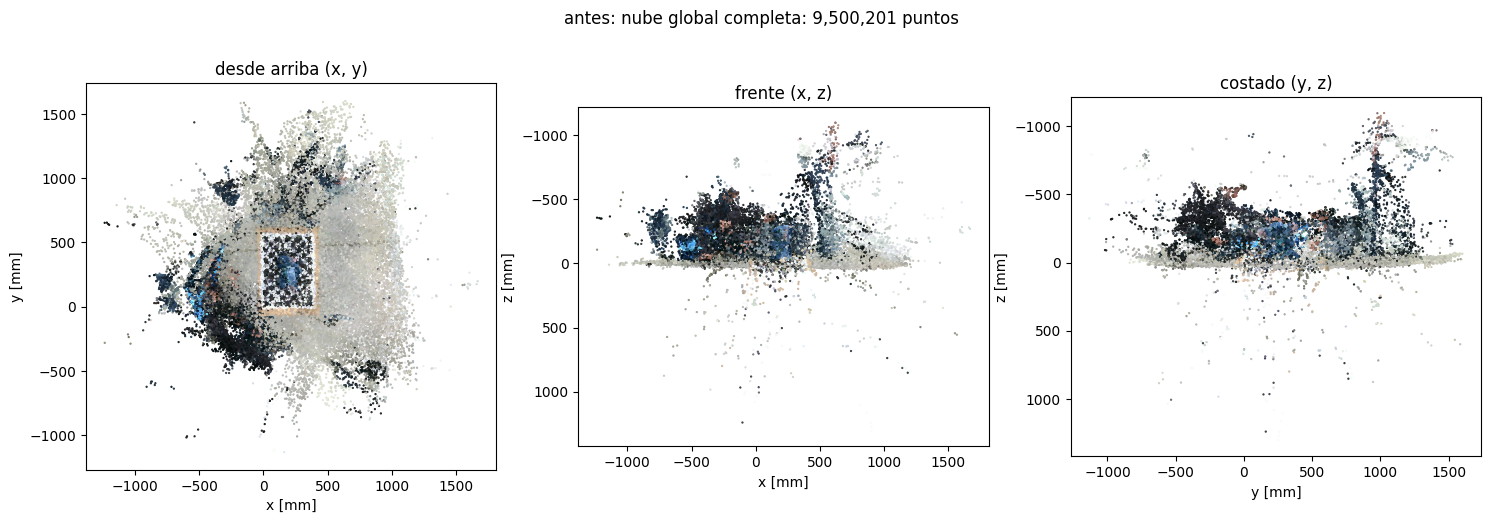

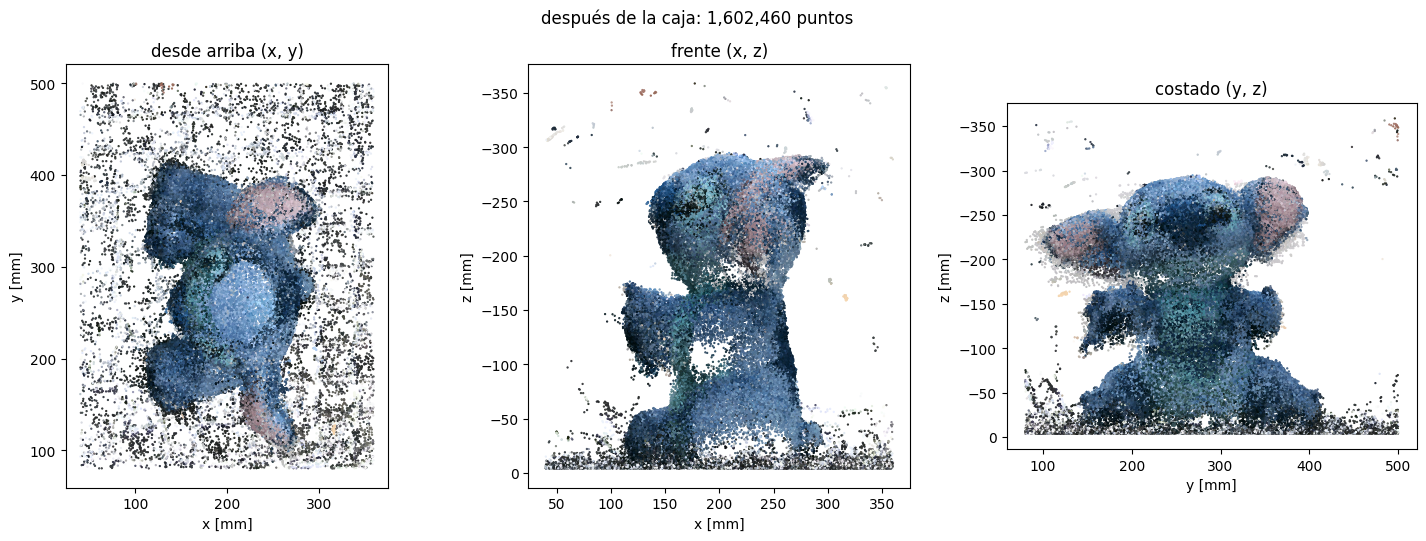

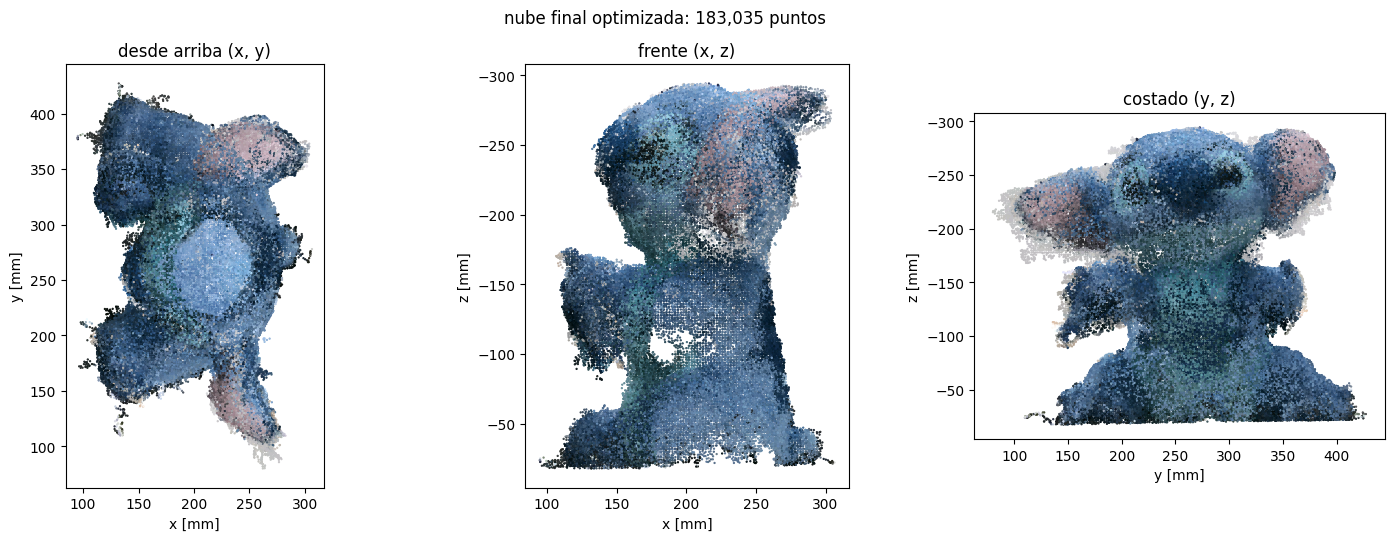

In [13]:
def plot_views(pcd, title, n=120_000):
    P, Cc = np.asarray(pcd.points), np.asarray(pcd.colors)
    s = np.random.default_rng(0).choice(len(P), min(n, len(P)), replace=False)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
    for a, (i, j, t) in zip(ax, [(0, 1, "desde arriba (x, y)"), (0, 2, "frente (x, z)"), (1, 2, "costado (y, z)")]):
        a.scatter(P[s, i], P[s, j], c=Cc[s], s=0.4); a.set_title(t); a.set_aspect("equal")
        a.set_xlabel("xyz"[i] + " [mm]"); a.set_ylabel("xyz"[j] + " [mm]")
    ax[1].invert_yaxis(); ax[2].invert_yaxis()
    fig.suptitle(f"{title}: {len(P):,} puntos"); plt.show()

plot_views(steps[0][1], "antes: nube global completa")
plot_views(steps[1][1], "después de la caja")
plot_views(pcd_final, "nube final optimizada")

In [14]:
out_dir = os.path.join(BASE, "outputs")
os.makedirs(out_dir, exist_ok=True)
ply_path = os.path.join(out_dir, "stitch_final.ply")
o3d.io.write_point_cloud(ply_path, pcd_final, write_ascii=False, compressed=False)
print(f"{ply_path}: {os.path.getsize(ply_path) / 1e6:.1f} MB, {len(pcd_final.points):,} puntos (PLY binario)")

../outputs/stitch_final.ply: 4.9 MB, 183,035 puntos (PLY binario)


## 10. Medición métrica, sección 5

Las coordenadas están en **mm reales** porque la escala entra dos veces en el pipeline: en el baseline $B$ de la calibración estéreo (z = f·B/d) y en el tamaño impreso del tablero (pose PnP). No es structure-from-motion monocular, donde la reconstrucción queda definida salvo un factor de escala. Además ya verificamos en la sección 5 que ambas escalas son consistentes (casillero triangulado de 42,2 mm frente a 42,0 mm).

Cómo medimos:
- **Alto**: distancia de cada punto al **plano del tablero ajustado** con RANSAC (no al plano z = 0 del PnP; ver la nota abajo). Alto = percentil 99,5 de esa distancia, para que un puñado de puntos espurios no lo infle. También reportamos el máximo. Entre corridas el resultado varía en ±1 mm (RANSAC).
- **Ancho y profundidad**: como el tablero define ejes horizontales naturales, proyectamos sobre el plano y calculamos el rectángulo mínimo (`cv2.minAreaRect`) que encierra el 99 % central de los puntos. El lado largo es el ancho de oreja a oreja.

**Nota sobre el plano**: el tablero reconstruido por estéreo aparece entre 7 y 10 mm por encima de z = 0 según la corrida de RANSAC (es el término `d` del plano de la sección 9). Es un sesgo sistemático entre la profundidad estéreo y la pose del PnP (≈1,5 % de la distancia de trabajo) y un buen punto para la discusión: viene de errores residuales de calibración (rectificación con 0,3 a 1,5 px de `dy`). Medir respecto al plano ajustado lo cancela para el alto.

normal del plano: [0.001 0.002 1.   ]  (≈ eje z del tablero)
ALTO           :  279.9 mm  (p99,5)   máx 285.8 mm
ANCHO (orejas) :  295.4 mm  (rectángulo mínimo del 99 % central, girado -90°)
PROFUNDIDAD    :  172.7 mm


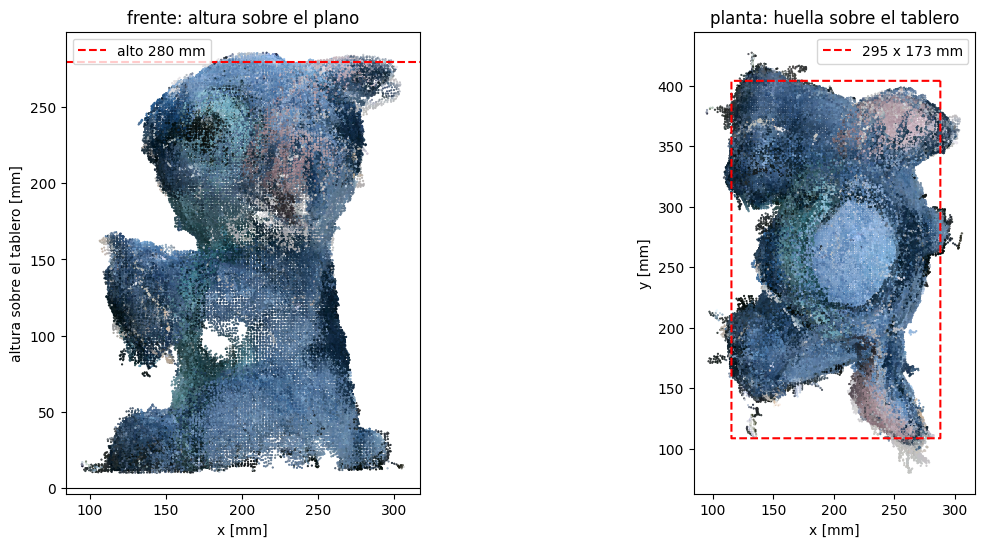

In [16]:
P = np.asarray(pcd_final.points)
n = plane[:3] / np.linalg.norm(plane[:3])
dist_plane = np.abs(P @ n + plane[3] / np.linalg.norm(plane[:3]))

alto_p995 = np.percentile(dist_plane, 99.5)
alto_max = dist_plane.max()

# proyección sobre el plano del tablero: usamos x, y del mundo (normal del plano ~ eje z)
xy = P[:, :2].astype(np.float32)
q = np.percentile(xy, [0.5, 99.5], axis=0)
core = np.all((xy >= q[0]) & (xy <= q[1]), axis=1)
(cx, cy), (w_rect, h_rect), ang = cv2.minAreaRect(xy[core])
ancho, prof = max(w_rect, h_rect), min(w_rect, h_rect)

print(f"normal del plano: {np.round(n, 3)}  (≈ eje z del tablero)")
print(f"ALTO           : {alto_p995:6.1f} mm  (p99,5)   máx {alto_max:.1f} mm")
print(f"ANCHO (orejas) : {ancho:6.1f} mm  (rectángulo mínimo del 99 % central, girado {ang:.0f}°)")
print(f"PROFUNDIDAD    : {prof:6.1f} mm")

REAL_ALTO_MM = None    # <- completar con la medida con regla del peluche
REAL_ANCHO_MM = None
for nombre, est, real in [("alto", alto_p995, REAL_ALTO_MM), ("ancho", ancho, REAL_ANCHO_MM)]:
    if real:
        print(f"error relativo {nombre}: {100 * (est - real) / real:+.1f} %  ({est:.1f} vs {real:.1f} mm)")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
Cc = np.asarray(pcd_final.colors)
ax[0].scatter(P[:, 0], dist_plane, c=Cc, s=0.3); ax[0].axhline(alto_p995, color="r", ls="--", label=f"alto {alto_p995:.0f} mm")
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_aspect("equal"); ax[0].legend(); ax[0].set_title("frente: altura sobre el plano")
ax[0].set_xlabel("x [mm]"); ax[0].set_ylabel("altura sobre el tablero [mm]")
ax[1].scatter(P[:, 0], P[:, 1], c=Cc, s=0.3)
box_pts = cv2.boxPoints(((cx, cy), (w_rect, h_rect), ang))
ax[1].plot(*np.vstack([box_pts, box_pts[:1]]).T, "r--", label=f"{ancho:.0f} x {prof:.0f} mm")
ax[1].set_aspect("equal"); ax[1].legend(); ax[1].set_title("planta: huella sobre el tablero")
ax[1].set_xlabel("x [mm]"); ax[1].set_ylabel("y [mm]")
plt.show()

## 11. Visualización interactiva en Open3D (opcional, local)

Abre ventanas de Open3D con el marco global, los frustums de cada cámara (`LineSet.create_camera_visualization`), la caja de recorte y la nube. No corre en Colab ni sin pantalla: dejar `SHOW_3D = False` para ejecutar el notebook de punta a punta.

In [19]:
SHOW_3D = False

if SHOW_3D:
    w, h = calibration["image_size"]
    geoms = [o3d.geometry.TriangleMesh.create_coordinate_frame(size=100)]
    for v in views:
        extr = np.eye(4); extr[:3, :3] = v["R_wc"]; extr[:3, 3] = v["t_wc"]
        cam = o3d.geometry.LineSet.create_camera_visualization(w, h, left_K, extr, scale=60)
        cam.paint_uniform_color([0.1, 0.3, 0.9]); geoms.append(cam)
    # nube global (submuestreada para que sea fluida) + caja de recorte
    o3d.visualization.draw_geometries(geoms + [pcd_all.voxel_down_sample(4.0), obb],
                                      window_name="poses de cámara y nube global")
    o3d.visualization.draw_geometries([pcd_final, o3d.geometry.TriangleMesh.create_coordinate_frame(size=50)],
                                      window_name="nube final optimizada")